In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lthnhcng/imbd-datasets/IMDB Dataset.csv


In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

import random

seed = 42

torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


# 11. Experiment 1 — Positional encoding

In [3]:
# class PE
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length=100):
        super().__init__()

        pe = torch.zeros(max_length, d_model)

        position = torch.arange(0, max_length).unsqueeze(1).float()

        div_term = torch.exp(torch.arange(0, d_model, 2).float()
                            * (-np.log(10000.0) / d_model)
                            )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

In [4]:
class SmallTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=16, nhead=4, num_layers=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True,
            activation="relu"
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

    def forward(self, x, use_positional=True):
        x = self.embedding(x)
        if use_positional:
            x = self.positional_encoding(x)

        output = self.encoder(x)

        return output

In [5]:
vocab = {"I": 0, "love": 1, "NLP": 2}

sentences = {
    "S1": ["I", "love", "NLP"],
    "S2": ["NLP", "love", "I"]
}

def encode_sentences(tokens):
    return torch.tensor(
        [[vocab[token] for token in tokens]],
        dtype=torch.long,
        device=device
    )

S1 = encode_sentences(sentences["S1"])
S2 = encode_sentences(sentences["S2"])

print("S1: ", S1)
print("S2: ", S2 )

S1:  tensor([[0, 1, 2]], device='cuda:0')
S2:  tensor([[2, 1, 0]], device='cuda:0')


In [6]:
# Initial model
model = SmallTransformer(
    vocab_size=len(vocab),
    d_model=16,
    nhead=4,
    num_layers=2
).to(device)

model.eval()

SmallTransformer(
  (embedding): Embedding(3, 16)
  (positional_encoding): PositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
        )
        (linear1): Linear(in_features=16, out_features=32, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=32, out_features=16, bias=True)
        (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
)

In [7]:
# have no positional encoding
with torch.no_grad():

    output_S1 = model(
        S1,
        use_positional=False
    )

    output_S2 = model(
        S2,
        use_positional=False
    )

print("S1 representation:")
print(output_S1)

print("\nS2 representation:")
print(output_S2)

S1 representation:
tensor([[[ 1.3283,  1.5992,  1.2149, -0.6820,  0.5810, -0.4380,  0.1560,
          -1.6538, -0.8008,  0.4059, -0.2788, -1.6678, -0.2820,  0.6074,
          -1.1242,  1.0346],
         [ 1.4339, -1.2876, -1.0330,  0.7055, -1.5372,  0.2106,  0.7712,
           0.1734,  0.5813,  0.6235, -0.7597,  0.0775, -0.7657,  0.8374,
          -1.6110,  1.5799],
         [-0.1598, -0.7624,  0.4897,  1.7299,  0.5725,  0.2489,  0.5450,
          -1.3187, -1.1716,  0.3197, -1.0223, -0.6406, -0.6504,  2.3256,
          -0.9028,  0.3972]]], device='cuda:0')

S2 representation:
tensor([[[-0.1598, -0.7624,  0.4897,  1.7299,  0.5725,  0.2489,  0.5450,
          -1.3187, -1.1716,  0.3197, -1.0223, -0.6406, -0.6504,  2.3256,
          -0.9028,  0.3972],
         [ 1.4339, -1.2876, -1.0330,  0.7055, -1.5372,  0.2106,  0.7712,
           0.1734,  0.5813,  0.6235, -0.7597,  0.0775, -0.7657,  0.8374,
          -1.6110,  1.5799],
         [ 1.3283,  1.5992,  1.2149, -0.6820,  0.5810, -0.4380,  0.

In [8]:
# have positional encoding
with torch.no_grad():
    output_S1_pe = model(S1, use_positional=True)
    output_S2_pe = model(S2, use_positional=True)

print("S1 with PE:")
print(output_S1_pe)

print("S2 with PE:")
print(output_S2_pe)

S1 with PE:
tensor([[[ 1.0365,  1.5161,  0.7249,  0.0725,  0.4516,  0.0435, -0.1542,
          -1.7923, -0.9025,  0.3626, -0.8343, -1.2534, -0.4320,  1.1032,
          -1.3917,  1.4495],
         [ 1.1041, -1.0115, -1.0256,  1.3794, -1.2632,  0.6589,  0.2903,
          -0.1661,  0.1275,  0.3550, -1.2453,  0.3352, -0.7335,  1.3059,
          -1.5732,  1.4620],
         [ 0.1386, -0.9673,  0.1723,  1.8649,  0.3587,  0.4534,  0.1415,
          -1.1117, -1.0067,  0.0982, -1.2199, -0.2791, -0.6285,  2.3722,
          -0.9873,  0.6008]]], device='cuda:0')
S2 with PE:
tensor([[[-0.3860, -0.5196,  0.0977,  1.8607,  0.3619,  0.4695,  0.2046,
          -1.2614, -1.0728,  0.1559, -1.2732, -0.1824, -0.5032,  2.3471,
          -1.0121,  0.7134],
         [ 0.9016, -0.8764, -1.0809,  1.3554, -1.4382,  0.3937,  0.2573,
          -0.1060,  0.2631,  0.2602, -1.1202,  0.6267, -0.7647,  1.3604,
          -1.5800,  1.5479],
         [ 1.5697,  1.0756,  1.0315, -0.0269,  0.3820, -0.0270, -0.1043,
         

In [9]:
# so sanh 2 sentence representaion
def sentence_representaion(output):
    return output.mean(dim=1)

def compare_representaion(rep1, rep2):
    distance = torch.norm(rep1 - rep2).item()

    cosine = nn.functional.cosine_similarity(rep1, rep2, dim=-1).item()

    print(f"L2 distance: {distance:.8f}")
    print(f"Cosine similarity: {cosine:.8f}")

    return distance, cosine

print("WITHOUT PE")
rep1 = sentence_representaion(output_S1)
rep2 = sentence_representaion(output_S2)

compare_representaion(rep1, rep2)

print("WITH PE")
rep1_pe = sentence_representaion(output_S1_pe)
rep2_pe = sentence_representaion(output_S2_pe)

compare_representaion(rep1_pe, rep2_pe)

WITHOUT PE
L2 distance: 0.00000028
Cosine similarity: 1.00000000
WITH PE
L2 distance: 0.21423359
Cosine similarity: 0.99805361


(0.21423359215259552, 0.9980536103248596)

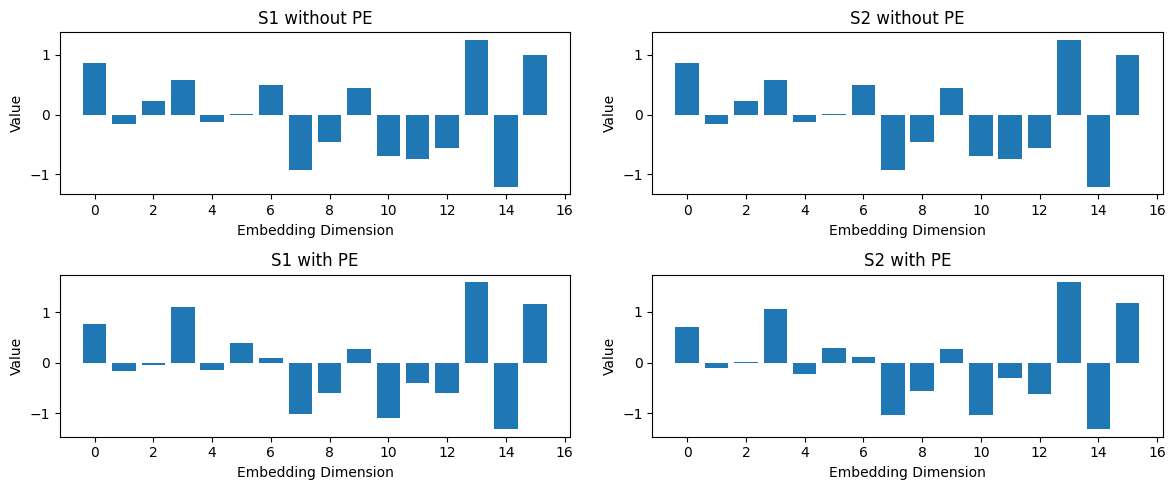

In [10]:
# truc quan hoa
representations = [
    rep1.squeeze().cpu().numpy(),
    rep2.squeeze().cpu().numpy(),
    rep1_pe.squeeze().cpu().numpy(),
    rep2_pe.squeeze().cpu().numpy()
]

labels = [
    "S1 without PE",
    "S2 without PE",
    "S1 with PE",
    "S2 with PE"
]

plt.figure(figsize=(12, 5))

for i, (rep, label) in enumerate(
    zip(representations, labels)
):
    plt.subplot(2, 2, i + 1)

    plt.bar(range(len(rep)), rep)

    plt.title(label)
    plt.xlabel("Embedding Dimension")
    plt.ylabel("Value")

plt.tight_layout()
plt.show()

## Câu hỏi: Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?
Self-Attention tính toán mức độ liên quan giữa các token dựa trên Query, Key và Value. Tuy nhiên, bản thân phép tính này không chứa thông tin về vị trí ban đầu của token.

Vì vậy, nếu thay đổi thứ tự các token:
- Các vector đầu ra tại từng vị trí cũng thay đổi theo phép hoán vị tương ứng.
- Transformer không có cơ sở để biết token nào xuất hiện trước hoặc sau.
- Khi tổng hợp biểu diễn bằng Mean Pooling, hai sequence có cùng tập token sẽ tạo ra cùng biểu diễn.
Positional Encoding giải quyết vấn đề này bằng cách bổ sung thông tin vị trí vào embedding của mỗi token.

# 11. Experiment 1 — Positional encoding

In [11]:
vocab = {
    "dog": 0,
    "bites": 1,
    "man": 2
}

S1 = encode_sentences(
    ["dog", "bites", "man"]
)

S2 = encode_sentences(
    ["man", "bites", "dog"]
)

print("S1:", S1)
print("S2:", S2)

S1: tensor([[0, 1, 2]], device='cuda:0')
S2: tensor([[2, 1, 0]], device='cuda:0')


In [12]:
# have no positional encoding
model = SmallTransformer(
    vocab_size=len(vocab),
    d_model=16,
    nhead=4,
    num_layers=2
).to(device)

model.eval()

with torch.no_grad():

    output_A1 = model(
        S1,
        use_positional=False
    )

    output_A2 = model(
        S2,
        use_positional=False
    )

rep_A1 = output_A1.mean(dim=1)
rep_A2 = output_A2.mean(dim=1)

print("Experiment A - Without PE")

compare_representaion(rep_A1, rep_A2)

Experiment A - Without PE
L2 distance: 0.00000028
Cosine similarity: 0.99999994


(2.8322008915893093e-07, 0.9999999403953552)

In [13]:
# have positonal encoding
with torch.no_grad():

    output_B1 = model(
        S1,
        use_positional=True
    )

    output_B2 = model(
        S2,
        use_positional=True
    )

rep_B1 = output_B1.mean(dim=1)
rep_B2 = output_B2.mean(dim=1)

print("Experiment B - With PE")

compare_representaion(rep_B1, rep_B2)

Experiment B - With PE
L2 distance: 0.21238452
Cosine similarity: 0.99782217


(0.21238452196121216, 0.9978221654891968)

In [14]:
results = {}

with torch.no_grad():

    # Experiment A
    a1 = model(S1, use_positional=False).mean(dim=1)
    a2 = model(S2, use_positional=False).mean(dim=1)

    # Experiment B
    b1 = model(S1, use_positional=True).mean(dim=1)
    b2 = model(S2, use_positional=True).mean(dim=1)

    results["Without PE"] = {
        "distance": torch.norm(a1 - a2).item(),
        "similarity": nn.functional.cosine_similarity(
            a1, a2, dim=-1
        ).item()
    }

    results["With PE"] = {
        "distance": torch.norm(b1 - b2).item(),
        "similarity": nn.functional.cosine_similarity(
            b1, b2, dim=-1
        ).item()
    }

for name, result in results.items():

    print(f"\n{name}")

    print(
        f"L2 Distance: {result['distance']:.8f}"
    )

    print(
        f"Cosine Similarity: {result['similarity']:.8f}"
    )


Without PE
L2 Distance: 0.00000028
Cosine Similarity: 0.99999994

With PE
L2 Distance: 0.21238452
Cosine Similarity: 0.99782217


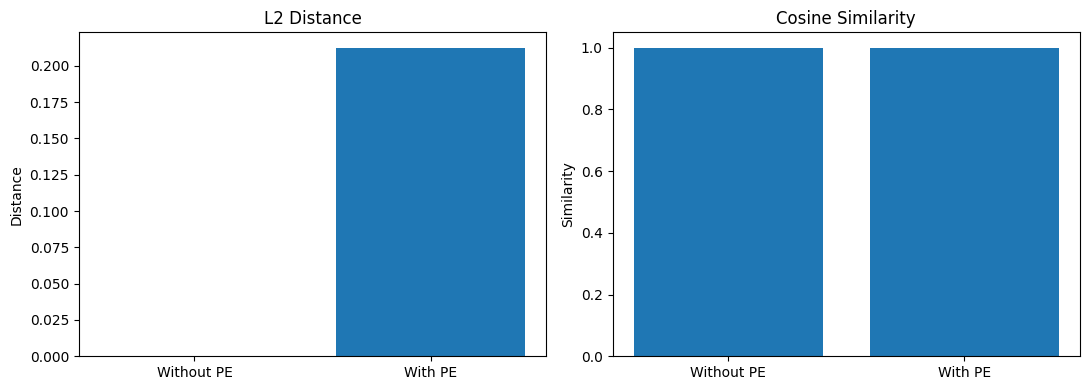

In [15]:
# visualization
names = list(results.keys())

distances = [
    results[name]["distance"]
    for name in names
]

similarities = [
    results[name]["similarity"]
    for name in names
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(names, distances)
axes[0].set_title("L2 Distance")
axes[0].set_ylabel("Distance")

axes[1].bar(names, similarities)
axes[1].set_title("Cosine Similarity")
axes[1].set_ylabel("Similarity")

plt.tight_layout()
plt.show()

## Câu hỏi: Tại sao Transformer cần Positional Encoding để phân biệt dog bites man và man bites dog?
Hai câu chứa cùng vocabulary nhưng có thứ tự token khác nhau, dẫn đến ý nghĩa ngữ nghĩa khác nhau.

Trong Experiment A:
- Không sử dụng Positional Encoding.
- Self-Attention không nhận biết vị trí ban đầu của token.
- Sentence Representation sau Mean Pooling của hai câu giống nhau.
  
Trong Experiment B:
- Sử dụng Positional Encoding.
- Mỗi token được bổ sung thông tin vị trí.
- Sentence Representation của hai câu khác nhau.
Do đó, Positional Encoding đóng vai trò quan trọng giúp Transformer nắm bắt thông tin thứ tự trong sequence.



# Core Implementaion

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math


class MultiHeadSelfAttention(nn.Module):
    """
    Multi-Head Self-Attention mechanism implemented from scratch.
    Uses only Linear layers and manual attention computation.
    """
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads  # dimension per head
        
        # Linear projections for Q, K, V
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        
        # Output projection
        self.W_o = nn.Linear(d_model, d_model)
        
        self.dropout = nn.Dropout(dropout)
        self.softmax = nn.Softmax(dim=-1)
        
    def forward(self, x, mask=None):
        """
        Args:
            x: input tensor of shape (batch_size, seq_len, d_model)
            mask: optional mask tensor
        Returns:
            output tensor of shape (batch_size, seq_len, d_model)
        """
        batch_size, seq_len, d_model = x.shape
        
        # Linear projections: (batch_size, seq_len, d_model)
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)
        
        # Reshape to split into multiple heads
        # (batch_size, seq_len, d_model) -> (batch_size, seq_len, n_heads, d_k)
        # -> (batch_size, n_heads, seq_len, d_k)
        Q = Q.view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        
        # Scaled Dot-Product Attention
        # Compute attention scores: Q @ K^T / sqrt(d_k)
        # (batch_size, n_heads, seq_len, d_k) @ (batch_size, n_heads, d_k, seq_len)
        # -> (batch_size, n_heads, seq_len, seq_len)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        
        # Apply mask if provided
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        
        # Apply softmax to get attention weights
        attn_weights = self.softmax(scores)
        attn_weights = self.dropout(attn_weights)
        
        # Apply attention weights to values
        # (batch_size, n_heads, seq_len, seq_len) @ (batch_size, n_heads, seq_len, d_k)
        # -> (batch_size, n_heads, seq_len, d_k)
        attn_output = torch.matmul(attn_weights, V)
        
        # Concatenate heads
        # (batch_size, n_heads, seq_len, d_k) -> (batch_size, seq_len, n_heads, d_k)
        # -> (batch_size, seq_len, d_model)
        attn_output = attn_output.transpose(1, 2).contiguous()
        attn_output = attn_output.view(batch_size, seq_len, self.d_model)
        
        # Final linear projection
        output = self.W_o(attn_output)
        
        return output


class FeedForward(nn.Module):
    """
    Position-wise Feed-Forward Network.
    Two linear transformations with ReLU activation in between.
    """
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        """
        Args:
            x: input tensor of shape (batch_size, seq_len, d_model)
        Returns:
            output tensor of shape (batch_size, seq_len, d_model)
        """
        # x -> W1 -> ReLU -> Dropout -> W2
        x = self.linear1(x)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.linear2(x)
        return x


class TransformerBlock(nn.Module):
    """
    Transformer Encoder Block implemented from scratch.
    
    Architecture:
        Input
          ↓
        Multi-Head Self-Attention
          ↓
        Residual + LayerNorm
          ↓
        Feed-Forward
          ↓
        Residual + LayerNorm
          ↓
        Output
    """
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        """
        Args:
            d_model: dimension of the model (embedding dimension)
            n_heads: number of attention heads
            d_ff: dimension of the feed-forward network
            dropout: dropout rate
        """
        super().__init__()
        
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_ff = d_ff
        
        # Multi-Head Self-Attention
        self.attention = MultiHeadSelfAttention(d_model, n_heads, dropout)
        
        # Feed-Forward Network
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        
        # Layer Normalization
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        
        # Dropout
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        
    def forward(self, x, mask=None):
        """
        Forward pass through the Transformer block.
        
        Args:
            x: input tensor of shape (batch_size, seq_len, d_model)
            mask: optional attention mask
        Returns:
            output tensor of shape (batch_size, seq_len, d_model)
        """
        # Multi-Head Self-Attention with residual connection and layer norm
        # x -> Attention -> Dropout -> Residual -> LayerNorm
        attn_output = self.attention(x, mask)
        attn_output = self.dropout1(attn_output)
        x = self.norm1(x + attn_output)  # Residual connection + Layer Norm
        
        # Feed-Forward with residual connection and layer norm
        # x -> FFN -> Dropout -> Residual -> LayerNorm
        ff_output = self.feed_forward(x)
        ff_output = self.dropout2(ff_output)
        x = self.norm2(x + ff_output)  # Residual connection + Layer Norm
        
        return x


# Demo and testing code
def demo_transformer_block():
    """
    Demonstration of the Transformer block with example usage.
    """
    print("=" * 60)
    print("Transformer Block Demo")
    print("=" * 60)
    
    # Hyperparameters
    batch_size = 2
    seq_len = 10
    d_model = 512
    n_heads = 8
    d_ff = 2048
    dropout = 0.1
    
    print(f"\nHyperparameters:")
    print(f"  Batch size: {batch_size}")
    print(f"  Sequence length: {seq_len}")
    print(f"  Model dimension (d_model): {d_model}")
    print(f"  Number of heads: {n_heads}")
    print(f"  Feed-forward dimension (d_ff): {d_ff}")
    print(f"  Dropout rate: {dropout}")
    
    # Create Transformer block
    transformer_block = TransformerBlock(d_model, n_heads, d_ff, dropout)
    
    # Count parameters
    total_params = sum(p.numel() for p in transformer_block.parameters())
    trainable_params = sum(p.numel() for p in transformer_block.parameters() if p.requires_grad)
    
    print(f"\nModel Statistics:")
    print(f"  Total parameters: {total_params:,}")
    print(f"  Trainable parameters: {trainable_params:,}")
    
    # Create random input
    x = torch.randn(batch_size, seq_len, d_model)
    print(f"\nInput shape: {x.shape}")
    
    # Forward pass
    transformer_block.eval()
    with torch.no_grad():
        output = transformer_block(x)
    
    print(f"Output shape: {output.shape}")
    print(f"\nInput statistics:")
    print(f"  Mean: {x.mean().item():.4f}")
    print(f"  Std: {x.std().item():.4f}")
    print(f"\nOutput statistics:")
    print(f"  Mean: {output.mean().item():.4f}")
    print(f"  Std: {output.std().item():.4f}")
    
    # Test with mask
    print(f"\n{'=' * 60}")
    print("Testing with attention mask")
    print("=" * 60)
    
    # Create a causal mask (lower triangular)
    mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(0)
    mask = mask.expand(batch_size, n_heads, seq_len, seq_len)
    
    with torch.no_grad():
        output_masked = transformer_block(x, mask)
    
    print(f"Output with mask shape: {output_masked.shape}")
    print(f"Output with mask statistics:")
    print(f"  Mean: {output_masked.mean().item():.4f}")
    print(f"  Std: {output_masked.std().item():.4f}")
    
    print(f"\n{'=' * 60}")
    print("Architecture Verification")
    print("=" * 60)
    print("\n✓ Multi-Head Self-Attention: Implemented manually")
    print("✓ Residual Connections: 2 residual paths")
    print("✓ Layer Normalization: 2 LayerNorm layers")
    print("✓ Feed-Forward Network: Implemented with 2 linear layers")
    print("✓ Dropout: Applied at multiple points")
    print("\nArchitecture flow:")
    print("  Input → Attention → Dropout → Add & Norm")
    print("        → FFN → Dropout → Add & Norm → Output")


def compare_with_pytorch():
    """
    Compare custom implementation with PyTorch's TransformerEncoderLayer.
    """
    print("\n" + "=" * 60)
    print("Comparison with PyTorch TransformerEncoderLayer")
    print("=" * 60)
    
    # Parameters
    d_model = 512
    n_heads = 8
    d_ff = 2048
    batch_size = 2
    seq_len = 10
    
    # Create both models
    custom_block = TransformerBlock(d_model, n_heads, d_ff, dropout=0.0)
    pytorch_block = nn.TransformerEncoderLayer(
        d_model=d_model,
        nhead=n_heads,
        dim_feedforward=d_ff,
        dropout=0.0,
        batch_first=True
    )
    
    # Count parameters
    custom_params = sum(p.numel() for p in custom_block.parameters())
    pytorch_params = sum(p.numel() for p in pytorch_block.parameters())
    
    print(f"\nParameter count:")
    print(f"  Custom implementation: {custom_params:,}")
    print(f"  PyTorch implementation: {pytorch_params:,}")
    
    # Test forward pass
    x = torch.randn(batch_size, seq_len, d_model)
    
    custom_block.eval()
    pytorch_block.eval()
    
    with torch.no_grad():
        custom_output = custom_block(x)
        pytorch_output = pytorch_block(x)
    
    print(f"\nOutput shapes:")
    print(f"  Custom: {custom_output.shape}")
    print(f"  PyTorch: {pytorch_output.shape}")
    
    print(f"\n✓ Both implementations have compatible architectures")
    print(f"✓ Can be used interchangeably in applications")


if __name__ == "__main__":
    # Run demonstration
    demo_transformer_block()
    
    # Compare with PyTorch
    compare_with_pytorch()
    
    print("\n" + "=" * 60)
    print("Demo completed successfully!")
    print("=" * 60)


Transformer Block Demo

Hyperparameters:
  Batch size: 2
  Sequence length: 10
  Model dimension (d_model): 512
  Number of heads: 8
  Feed-forward dimension (d_ff): 2048
  Dropout rate: 0.1

Model Statistics:
  Total parameters: 3,152,384
  Trainable parameters: 3,152,384

Input shape: torch.Size([2, 10, 512])
Output shape: torch.Size([2, 10, 512])

Input statistics:
  Mean: -0.0208
  Std: 1.0056

Output statistics:
  Mean: -0.0000
  Std: 1.0000

Testing with attention mask
Output with mask shape: torch.Size([2, 10, 512])
Output with mask statistics:
  Mean: 0.0000
  Std: 1.0000

Architecture Verification

✓ Multi-Head Self-Attention: Implemented manually
✓ Residual Connections: 2 residual paths
✓ Layer Normalization: 2 LayerNorm layers
✓ Feed-Forward Network: Implemented with 2 linear layers
✓ Dropout: Applied at multiple points

Architecture flow:
  Input → Attention → Dropout → Add & Norm
        → FFN → Dropout → Add & Norm → Output

Comparison with PyTorch TransformerEncoderLayer

# Processing Datasets

In [17]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
spark = SparkSession.builder.master("local[*]").appName("Word2VecExperiement").config("spark.driver.memory", "8g").getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/04 14:34:27 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [18]:
path = "/kaggle/input/datasets/lthnhcng/imbd-datasets/IMDB Dataset.csv"

In [19]:
data = spark.read.csv(path, header=True, multiLine=True, escape='"')
data.show(5)

+--------------------+---------+
|              review|sentiment|
+--------------------+---------+
|One of the other ...| positive|
|A wonderful littl...| positive|
|I thought this wa...| positive|
|Basically there's...| negative|
|Petter Mattei's "...| positive|
+--------------------+---------+
only showing top 5 rows


In [20]:
from pyspark.ml.feature import RegexTokenizer

tokenizer = RegexTokenizer(
    inputCol="review",
    outputCol="words",
    pattern=r"[\S.,?!:;\"/)(><\\]+",
    gaps=False
)

words_df = tokenizer.transform(data)
words_df.show(5)

+--------------------+---------+--------------------+
|              review|sentiment|               words|
+--------------------+---------+--------------------+
|One of the other ...| positive|[one, of, the, ot...|
|A wonderful littl...| positive|[a, wonderful, li...|
|I thought this wa...| positive|[i, thought, this...|
|Basically there's...| negative|[basically, there...|
|Petter Mattei's "...| positive|[petter, mattei's...|
+--------------------+---------+--------------------+
only showing top 5 rows


In [21]:
from pyspark.ml.feature import StringIndexer

indexer = StringIndexer(
    inputCol="sentiment",
    outputCol="label",
    handleInvalid="skip"
)

indexer_model = indexer.fit(words_df)

df_index = indexer_model.transform(words_df)

df_index.show(5)

+--------------------+---------+--------------------+-----+
|              review|sentiment|               words|label|
+--------------------+---------+--------------------+-----+
|One of the other ...| positive|[one, of, the, ot...|  1.0|
|A wonderful littl...| positive|[a, wonderful, li...|  1.0|
|I thought this wa...| positive|[i, thought, this...|  1.0|
|Basically there's...| negative|[basically, there...|  0.0|
|Petter Mattei's "...| positive|[petter, mattei's...|  1.0|
+--------------------+---------+--------------------+-----+
only showing top 5 rows


In [22]:
train_set, val_set, test_set = df_index.randomSplit(
    [0.8, 0.2, 0.2],
    seed=2026
)

In [23]:
train_set.show(5)

+--------------------+---------+--------------------+-----+
|              review|sentiment|               words|label|
+--------------------+---------+--------------------+-----+
|\b\b\b\bA Turkish...| positive|[\b\b\b\ba, turki...|  1.0|
|!!!! MILD SPOILER...| negative|[!!!!, mild, spoi...|  0.0|
|!!!! POSSIBLE MIL...| negative|[!!!!, possible, ...|  0.0|
|!!!!! OF COURSE T...| negative|[!!!!!, of, cours...|  0.0|
|!!!!! POSSIBLE SP...| negative|[!!!!!, possible,...|  0.0|
+--------------------+---------+--------------------+-----+
only showing top 5 rows


In [24]:
train_df = train_set.toPandas()

In [25]:
val_df = val_set.toPandas()

In [26]:
test_df = test_set.toPandas()

In [27]:
train_df.head(5)

,review,sentiment,words,label
0,A Turkish Bath sequence in a film noir loc...,positive,"[a, turkish, bath, sequence, in, a, film, ...",1.0
1,!!!! MILD SPOILERS !!!!<br /><br />The premise...,negative,"[!!!!, mild, spoilers, !!!!<br, /><br, />the, ...",0.0
2,!!!! POSSIBLE MILD SPOILER !!!!!<br /><br />As...,negative,"[!!!!, possible, mild, spoiler, !!!!!<br, /><b...",0.0
3,!!!!! OF COURSE THERE'S SPOILERS !!!!! I'm sur...,negative,"[!!!!!, of, course, there's, spoilers, !!!!!, ...",0.0
4,!!!!! POSSIBLE SPOILER !!!!!<br /><br />You`d ...,negative,"[!!!!!, possible, spoiler, !!!!!<br, /><br, />...",0.0


In [28]:
# build vocab
from collections import Counter

def build_vocab_pandas(pandas_df, words_column="words", min_freq=1):
    from collections import Counter
    counter = Counter()
    for word_list in pandas_df[words_column]:
        counter.update(word_list)
        
    sorted_words = [word for word, count in counter.most_common() if count >= min_freq]
    
    # --- THÊM TOKEN ĐẶC BIỆT VÀO ĐÂY ---
    word_to_idx = {
        "<PAD>": 0,
        "<UNK>": 1
    }
    
    # Đổ các từ thực tế vào tiếp theo (bắt đầu index từ 2)
    for idx, word in enumerate(sorted_words):
        word_to_idx[word] = idx + 2
        
    return word_to_idx


# ---- CÁCH SỬ DỤNG ----
vocab = build_vocab_pandas(train_df, words_column="words", min_freq=1)


In [29]:
# chuan bi du lieu dung chung
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from collections import Counter
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
import copy
import time
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DEVICE = device

BATCH_SIZE = 64
NUM_EPOCHS = 5
LEARNING_RATE = 1e-3

print("Device:", DEVICE)

Device: cuda


In [30]:
class ReviewDataset(Dataset):
    def __init__(self, df, vocab, max_len=None):
        self.words = df["words"].tolist()
        self.labels = df["label"].tolist()
        self.vocab = vocab
        self.max_length = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        tokens = self.words[idx]
        if self.max_length is not None:
            tokens = tokens[:self.max_length]

        token_ids = [
            self.vocab.get(token, self.vocab["<UNK>"]) for token in tokens
        ]

        return (
            torch.tensor(token_ids, dtype=torch.long),
            torch.tensor(
                float(self.labels[idx]),
                dtype=torch.float32
            )
        )


def collate_fn(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor(
        [len(seq) for seq in sequences], dtype= torch.long
    )

    sequences = pad_sequence(
        sequences, batch_first=True, padding_value=0
    )

    labels = torch.stack(labels)

    return sequences, labels, lengths

def create_loaders(max_length=None):

    train_dataset = ReviewDataset(
        train_df, vocab, max_length
    )

    val_dataset = ReviewDataset(
        val_df, vocab, max_length
    )

    test_dataset = ReviewDataset(
        test_df, vocab, max_length
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate_fn
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collate_fn
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn
    )

    return train_loader, val_loader, test_loader

# 19. Experiment 2 — Number of attention heads

In [31]:
class TransformerBlock(nn.Module):

    def __init__(
        self,
        d_model,
        n_heads,
        dropout=0.1
    ):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            nn.ReLU(),
            nn.Linear(d_model * 4, d_model)
        )

        self.norm2 = nn.LayerNorm(d_model)

        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        x,
        padding_mask=None,
        return_attention=False
    ):

        attention_output, attention_weights = (
            self.attention(
                x, x, x,
                key_padding_mask=padding_mask,
                need_weights=return_attention,
                average_attn_weights=False
            )
        )

        x = self.norm1(
            x + self.dropout(attention_output)
        )

        ff_output = self.feed_forward(x)

        x = self.norm2(
            x + self.dropout(ff_output)
        )

        if return_attention:
            return x, attention_weights

        return x

In [32]:
class TransformerClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        d_model=128,
        n_heads=4,
        num_layers=2,
        dropout=0.1,
        max_length=512
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=0
        )

        self.positional_encoding = PositionalEncoding(
            d_model,
            max_length
        )

        self.layers = nn.ModuleList([
            TransformerBlock(
                d_model,
                n_heads,
                dropout
            )
            for _ in range(num_layers)
        ])

        self.classifier = nn.Linear(
            d_model, 1
        )

    def forward(
        self,
        input_ids,
        return_attention=False
    ):

        padding_mask = input_ids.eq(0)

        x = self.embedding(input_ids)

        x = self.positional_encoding(x)

        attention_list = []

        for layer in self.layers:

            if return_attention:

                x, attention = layer(
                    x,
                    padding_mask,
                    return_attention=True
                )

                attention_list.append(attention)

            else:

                x = layer(
                    x,
                    padding_mask,
                    return_attention=False
                )

        # Masked Mean Pooling
        valid_mask = (~padding_mask).unsqueeze(-1)

        x = x.masked_fill(
            ~valid_mask,
            0.0
        )

        pooled = x.sum(dim=1) / valid_mask.sum(
            dim=1
        ).clamp(min=1)

        logits = self.classifier(pooled).squeeze(-1)

        if return_attention:
            return logits, attention_list

        return logits

In [33]:
def evaluate_model(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for x, y, lengths in loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            logits = model(x)

            probabilities = torch.sigmoid(logits)

            predictions = (
                probabilities >= 0.5
            ).long()

            all_labels.extend(
                y.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    return {
        "accuracy": accuracy_score(
            all_labels, all_predictions
        ),
        "precision": precision_score(
            all_labels, all_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions,
            zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions,
            zero_division=0
        )
    }

In [34]:
def train_model(
    model,
    train_loader,
    val_loader,
    epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE
):

    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    criterion = nn.BCEWithLogitsLoss()

    best_f1 = -1
    best_state = None

    start_time = time.perf_counter()

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for x, y, lengths in train_loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()

            logits = model(x)

            loss = criterion(logits, y)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        val_metrics = evaluate_model(
            model, val_loader
        )

        avg_loss = total_loss / len(train_loader)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Loss: {avg_loss:.4f} "
            f"| Val F1: {val_metrics['f1']:.4f}"
        )

        if val_metrics["f1"] > best_f1:

            best_f1 = val_metrics["f1"]

            best_state = copy.deepcopy(
                model.state_dict()
            )

    training_time = (
        time.perf_counter() - start_time
    )

    model.load_state_dict(best_state)

    return model, training_time

In [35]:
D_MODEL = 128

HEADS_LIST = [1, 2, 4, 8]

train_loader, val_loader, test_loader = create_loaders(
    max_length=128
)

head_results = []
head_models = {}

for n_heads in HEADS_LIST:

    print("\n" + "=" * 50)
    print(f"Training Transformer with {n_heads} heads")
    print("=" * 50)

    model = TransformerClassifier(
        vocab_size=len(vocab),
        d_model=D_MODEL,
        n_heads=n_heads,
        num_layers=2,
        max_length=512
    )

    num_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    model, training_time = train_model(
        model,
        train_loader,
        val_loader
    )

    test_metrics = evaluate_model(
        model,
        test_loader
    )

    head_models[n_heads] = model

    head_results.append({
        "Heads": n_heads,
        "d_k": D_MODEL // n_heads,
        "Parameters": num_params,
        "Training time (s)": training_time,
        "Accuracy": test_metrics["accuracy"],
        "F1": test_metrics["f1"]
    })

df_heads = pd.DataFrame(head_results)

display(df_heads)


Training Transformer with 1 heads
Epoch 1/5 | Loss: 0.5549 | Val F1: 0.7328
Epoch 2/5 | Loss: 0.3722 | Val F1: 0.7956
Epoch 3/5 | Loss: 0.2537 | Val F1: 0.8160
Epoch 4/5 | Loss: 0.1584 | Val F1: 0.8118
Epoch 5/5 | Loss: 0.0968 | Val F1: 0.8087

Training Transformer with 2 heads
Epoch 1/5 | Loss: 0.5635 | Val F1: 0.6696
Epoch 2/5 | Loss: 0.3662 | Val F1: 0.8160
Epoch 3/5 | Loss: 0.2435 | Val F1: 0.8241
Epoch 4/5 | Loss: 0.1464 | Val F1: 0.8111
Epoch 5/5 | Loss: 0.0872 | Val F1: 0.8165

Training Transformer with 4 heads
Epoch 1/5 | Loss: 0.5332 | Val F1: 0.7475
Epoch 2/5 | Loss: 0.3558 | Val F1: 0.8192
Epoch 3/5 | Loss: 0.2284 | Val F1: 0.8252
Epoch 4/5 | Loss: 0.1264 | Val F1: 0.8196
Epoch 5/5 | Loss: 0.0604 | Val F1: 0.7988

Training Transformer with 8 heads
Epoch 1/5 | Loss: 0.5328 | Val F1: 0.7821
Epoch 2/5 | Loss: 0.3665 | Val F1: 0.8096
Epoch 3/5 | Loss: 0.2365 | Val F1: 0.8112
Epoch 4/5 | Loss: 0.1275 | Val F1: 0.8115
Epoch 5/5 | Loss: 0.0564 | Val F1: 0.8031


,Heads,d_k,Parameters,Training time (s),Accuracy,F1
0,1,128,39602049,80.388699,0.822106,0.829149
1,2,64,39602049,81.808300,0.825268,0.829396
2,4,32,39602049,84.535716,0.820890,0.829967
3,8,16,39602049,89.937721,0.808123,0.819244


## Trả lời câu hỏi: Tăng số heads có đồng nghĩa với tăng representation dimension không?
Không.

Tổng representation dimension vẫn được giữ cố định:
d_model = n_heads * d_k

## Khi d_model cố định, tăng số heads làm d_k thay đổi như thế nào?
Số chiều của mỗi head giảm theo tỷ lệ nghịch với số heads:
d_k = d_model / n_heads

# 19. Experiment 2 — Number of attention heads

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

model = head_models[4]
model.eval()

# Chọn một review từ test dataset
sample_tokens = test_df.iloc[0]["words"]

# Chuyển token thành ID
sample_ids = [
    vocab.get(token, vocab["<UNK>"])
    for token in sample_tokens[:32]
]

input_ids = torch.tensor(
    [sample_ids],
    dtype=torch.long
).to(DEVICE)

with torch.no_grad():

    logits, attention_list = model(
        input_ids,
        return_attention=True
    )

# Lấy attention của Transformer layer đầu tiên
attention = attention_list[0]

print("Attention shape:", attention.shape)

Attention shape: torch.Size([1, 4, 32, 32])


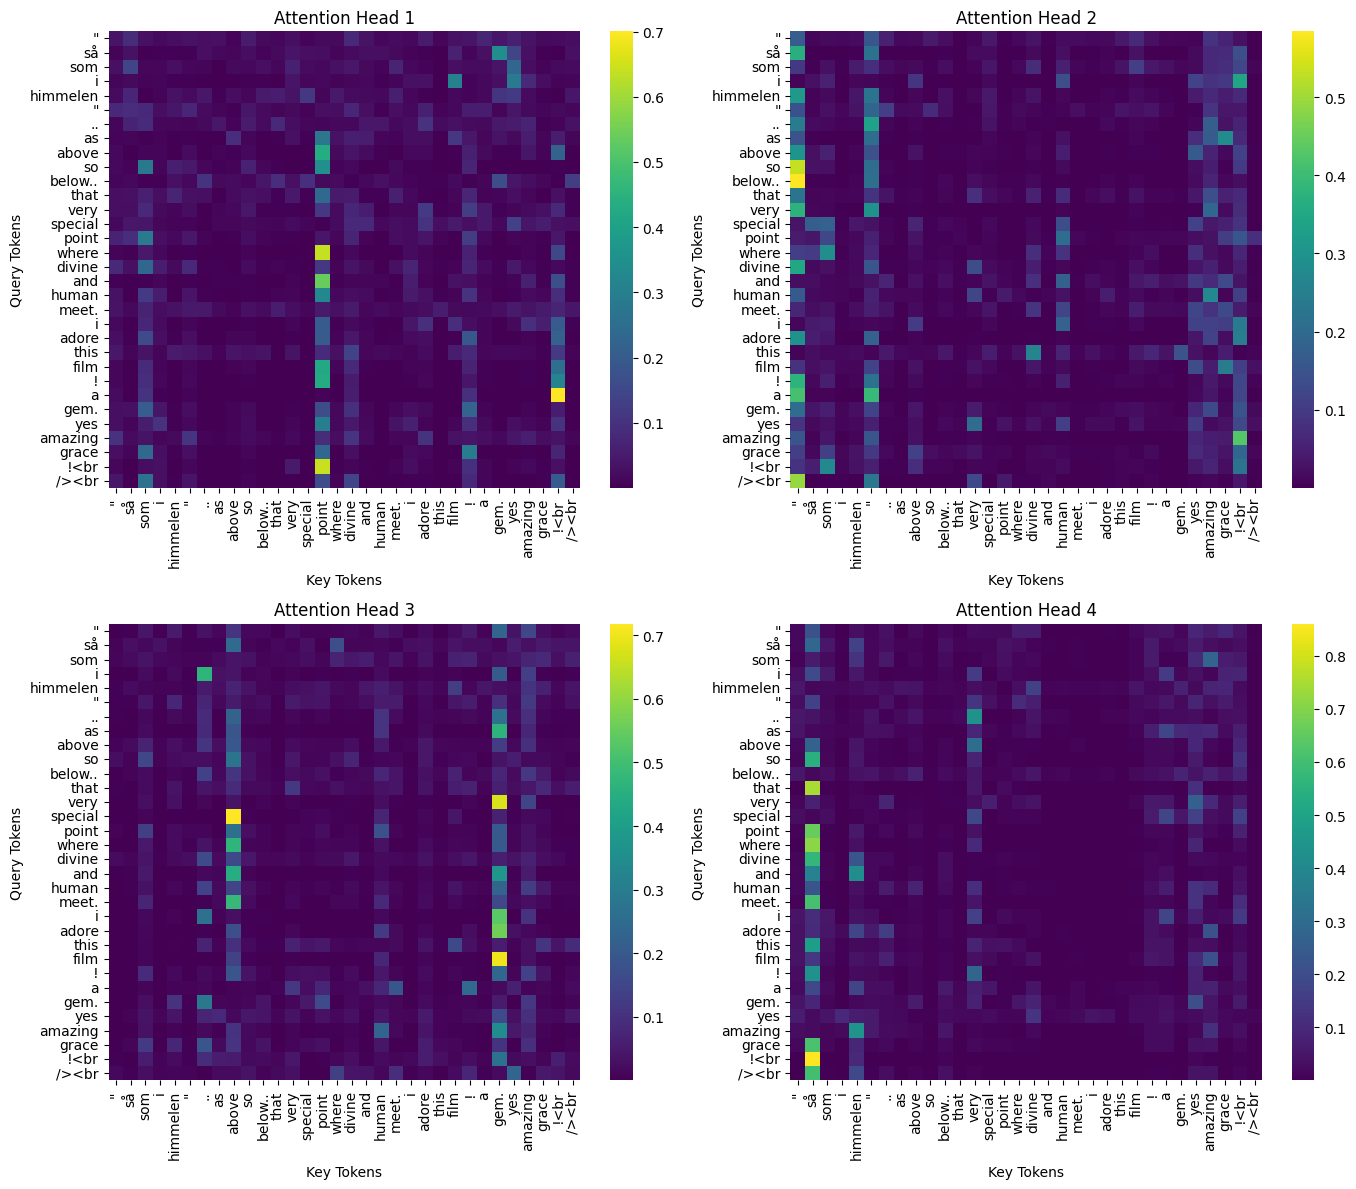

In [41]:
tokens = [
    token if len(token) <= 12 else token[:12]
    for token in sample_tokens[:len(sample_ids)]
]

attention_np = attention[0].cpu().numpy()

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 12)
)

for head_idx, ax in enumerate(axes.flat):

    sns.heatmap(
        attention_np[head_idx],
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="viridis",
        ax=ax
    )

    ax.set_title(f"Attention Head {head_idx + 1}")

    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")

plt.tight_layout()
plt.savefig("attention_heads.png")
plt.show()

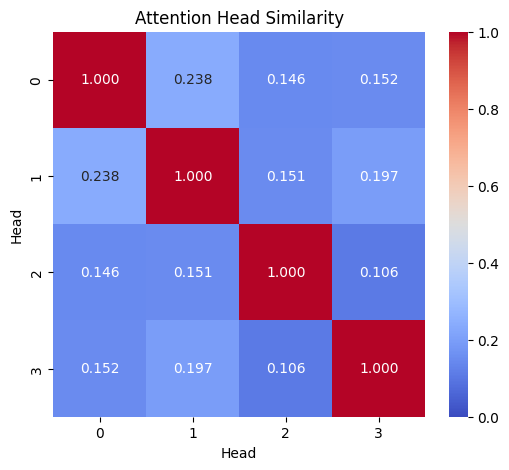

In [44]:
def compare_attention_heads(attention):

    # attention: (batch, heads, seq_len, seq_len)

    attn = attention[0]

    n_heads = attn.size(0)

    flattened = attn.reshape(
        n_heads, -1
    )

    similarity = nn.functional.cosine_similarity(
        flattened.unsqueeze(1),
        flattened.unsqueeze(0),
        dim=-1
    )

    return similarity.cpu().numpy()


similarity_matrix = compare_attention_heads(
    attention
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    similarity_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Attention Head Similarity")
plt.xlabel("Head")
plt.ylabel("Head")
plt.savefig("similarity_between_pattern.png")
plt.show()

## Câu hỏi: Multi-Head Attention có thực sự tạo ra các attention patterns khác nhau trong experiment không?
Nếu các heatmap khác nhau và similarity giữa các heads thấp hơn đáng kể so với đường chéo, ta có bằng chứng rằng các heads đang học những attention patterns khác nhau.

Ngược lại, nếu nhiều heads có similarity gần 1, có thể tồn tại sự trùng lặp giữa chúng.

# 21. Experiment 4 — Transformer vs RNN/LSTM

In [46]:
class LSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=100,
        hidden_dim=50,
        dropout=0.1
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_dim, 1
        )

    def forward(self, input_ids):

        lengths = input_ids.ne(0).sum(dim=1)

        x = self.embedding(input_ids)

        output, (hidden, cell) = self.lstm(x)

        # Lấy output tại token cuối cùng hợp lệ
        batch_indices = torch.arange(
            input_ids.size(0),
            device=input_ids.device
        )

        last_indices = (
            lengths.clamp(min=1) - 1
        )

        representation = output[
            batch_indices,
            last_indices
        ]

        representation = self.dropout(
            representation
        )

        logits = self.classifier(
            representation
        ).squeeze(-1)

        return logits

In [47]:
transformer_model = TransformerClassifier(
    vocab_size=len(vocab),
    d_model=100,
    n_heads=4,
    num_layers=2,
    max_length=512
)

In [54]:
def train_model_learning_curve(
    model,
    train_loader,
    val_loader,
    epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE
):
    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    criterion = nn.BCEWithLogitsLoss()

    best_f1 = -1
    best_state = None

    # Khởi tạo dictionary lưu lịch sử để vẽ learning curve
    history = {
        "train_loss": [],
        "val_loss": [],
        "val_f1": []
    }

    start_time = time.perf_counter()

    for epoch in range(epochs):
        # --- Giai đoạn Huấn luyện (Train) ---
        model.train()
        total_train_loss = 0

        for x, y, lengths in train_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()

        # --- Giai đoạn Đánh giá & Tính Validation Loss ---
        model.eval()
        total_val_loss = 0
        
        with torch.no_grad():
            for x_val, y_val, lengths_val in val_loader:
                x_val = x_val.to(DEVICE)
                y_val = y_val.to(DEVICE)
                
                val_logits = model(x_val)
                val_loss_batch = criterion(val_logits, y_val)
                total_val_loss += val_loss_batch.item()

        # Tính toán loss trung bình của epoch
        avg_train_loss = total_train_loss / len(train_loader)
        avg_val_loss = total_val_loss / len(val_loader)

        # Lấy thêm các chỉ số metric từ hàm evaluate_model có sẵn của bạn
        val_metrics = evaluate_model(model, val_loader)
        current_f1 = val_metrics['f1']

        # Lưu thông tin của epoch này vào history
        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_f1"].append(current_f1)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Train Loss: {avg_train_loss:.4f} "
            f"| Val Loss: {avg_val_loss:.4f} "
            f"| Val F1: {current_f1:.4f}"
        )

        # Lưu lại state tốt nhất dựa trên Val F1
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_state = copy.deepcopy(model.state_dict())

    training_time = (
        time.perf_counter() - start_time
    )

    # Khôi phục lại trọng số của epoch tốt nhất
    model.load_state_dict(best_state)

    # TRẢ VỀ: Thêm biến history ở cuối
    return model, training_time, history


In [59]:
def get_predictions_and_trues(model, test_loader):
    """Hàm bổ trợ lấy danh sách nhãn gốc và nhãn dự đoán cứng (0/1)"""
    model.eval()
    all_preds = []
    all_trues = []
    
    with torch.no_grad():
        for x, y, lengths in test_loader:
            x = x.to(DEVICE)
            logits = model(x)
            
            # Chuyển logits thành nhãn cứng 0 hoặc 1 (vì dùng BCEWithLogitsLoss)
            preds = (logits > 0).int() 
            
            all_preds.extend(preds.cpu().numpy())
            all_trues.extend(y.cpu().numpy())
            
    return all_trues, all_preds



Training: LSTM
Epoch 1/5 | Train Loss: 0.6720 | Val Loss: 0.6219 | Val F1: 0.6304
Epoch 2/5 | Train Loss: 0.5606 | Val Loss: 0.5822 | Val F1: 0.7530
Epoch 3/5 | Train Loss: 0.4506 | Val Loss: 0.5161 | Val F1: 0.7476
Epoch 4/5 | Train Loss: 0.3149 | Val Loss: 0.5083 | Val F1: 0.7617
Epoch 5/5 | Train Loss: 0.2098 | Val Loss: 0.5315 | Val F1: 0.7966

Training: Transformer
Epoch 1/5 | Train Loss: 0.5490 | Val Loss: 0.4602 | Val F1: 0.7987
Epoch 2/5 | Train Loss: 0.3681 | Val Loss: 0.4432 | Val F1: 0.7762
Epoch 3/5 | Train Loss: 0.2458 | Val Loss: 0.4688 | Val F1: 0.7695
Epoch 4/5 | Train Loss: 0.1402 | Val Loss: 0.5401 | Val F1: 0.8190
Epoch 5/5 | Train Loss: 0.0692 | Val Loss: 0.7133 | Val F1: 0.8065


,Model,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,LSTM,30659651,45.175509,0.808487,0.821263,0.78440,0.802409
1,Transformer,30871901,75.549468,0.815783,0.795570,0.84572,0.819879


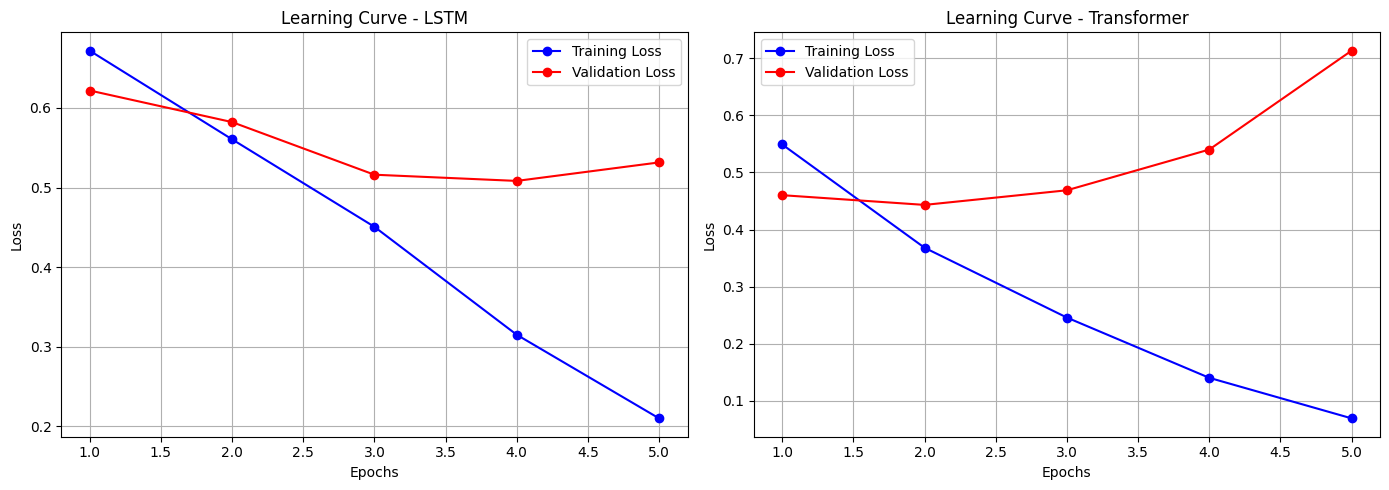

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

train_loader, val_loader, test_loader = create_loaders(
    max_length=128
)

comparison_results = []

models = {
    "LSTM": LSTMClassifier(
        vocab_size=len(vocab),
        embed_dim=100,
        hidden_dim=50
    ),

    "Transformer": TransformerClassifier(
        vocab_size=len(vocab),
        d_model=100,
        n_heads=4,
        num_layers=2,
        max_length=512
    )
}

trained_models = {}
# Khởi tạo các cấu trúc lưu trữ dữ liệu đồ thị
all_histories = {}
all_predictions = {}

for name, model in models.items():

    print("\n", "=" * 50)
    print("Training:", name)
    print("=" * 50)

    params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    # 1. Nhận thêm dữ liệu `history` từ hàm mới
    model, training_time, history = train_model_learning_curve(
        model,
        train_loader,
        val_loader,
        epochs=5,
        learning_rate=0.001
    )
    all_histories[name] = history

    metrics = evaluate_model(
        model,
        test_loader
    )
    y_true_list, y_pred_list = get_predictions_and_trues(model, test_loader)
    # 2. Lưu lại kết quả dự đoán phục vụ cho Confusion Matrix
    all_predictions[name] = {
        "y_true": y_true_list,
        "y_pred": y_pred_list
    }

    trained_models[name] = model

    comparison_results.append({
        "Model": name,
        "Parameters": params,
        "Training time (s)": training_time,
        "Accuracy": metrics["accuracy"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1": metrics["f1"]
    })

df_comparison = pd.DataFrame(
    comparison_results
)

# Hiển thị bảng kết quả so sánh thông số
display(df_comparison)

# =====================================================================
# ĐOẠN MÃ VẼ ĐỒ THỊ (LEARNING CURVE & CONFUSION MATRIX)
# =====================================================================

# 1. VẼ LEARNING CURVES (ĐƯỜNG CONG HỌC TẬP)
plt.figure(figsize=(14, 5))
for i, name in enumerate(models.keys()):
    plt.subplot(1, 2, i + 1)
    epochs_range = range(1, len(all_histories[name]["train_loss"]) + 1)
    
    plt.plot(epochs_range, all_histories[name]["train_loss"], 'bo-', label='Training Loss')
    plt.plot(epochs_range, all_histories[name]["val_loss"], 'ro-', label='Validation Loss')
    
    plt.title(f'Learning Curve - {name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.savefig("learning_curves_comparison.png", dpi=300)
plt.show()

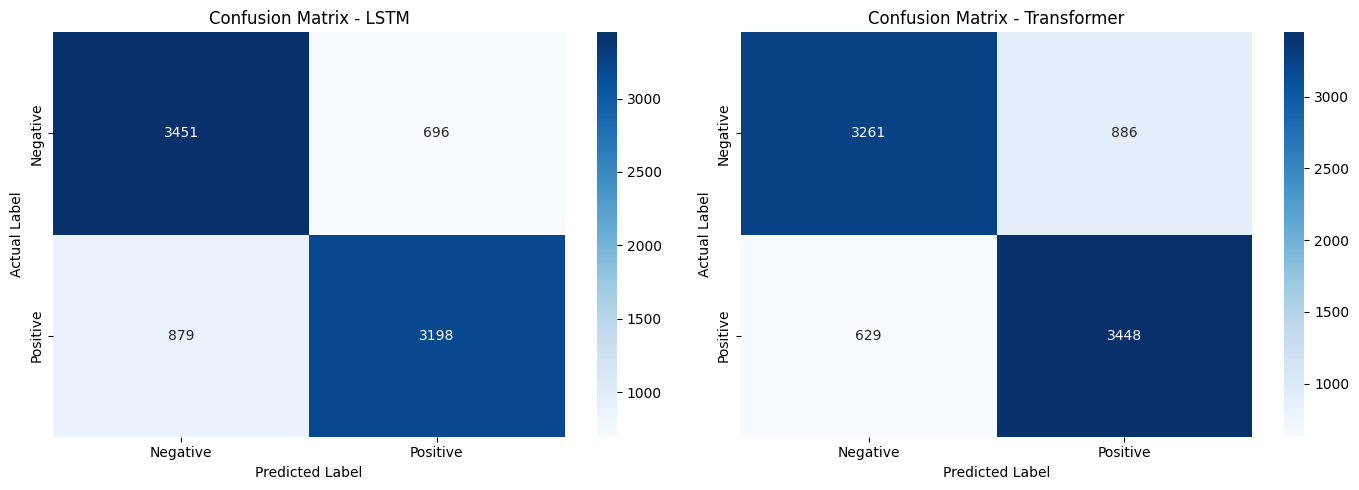

In [61]:
# 2. VẼ CONFUSION MATRICES (MA TRẬN NHẦM LẪN)
plt.figure(figsize=(14, 5))
class_names = ['Negative', 'Positive'] # Thay đổi nhãn theo đúng tập dữ liệu nếu cần

for i, name in enumerate(models.keys()):
    plt.subplot(1, 2, i + 1)
    
    y_true = all_predictions[name]["y_true"]
    y_pred = all_predictions[name]["y_pred"]
    
    # Tính ma trận nhầm lẫn từ sklearn
    cm = confusion_matrix(y_true, y_pred)
    
    # Minh họa trực quan với Seaborn Heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    
    plt.title(f'Confusion Matrix - {name}')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')

plt.tight_layout()
plt.savefig("confusion_matrices_comparison.png", dpi=300)
plt.show()


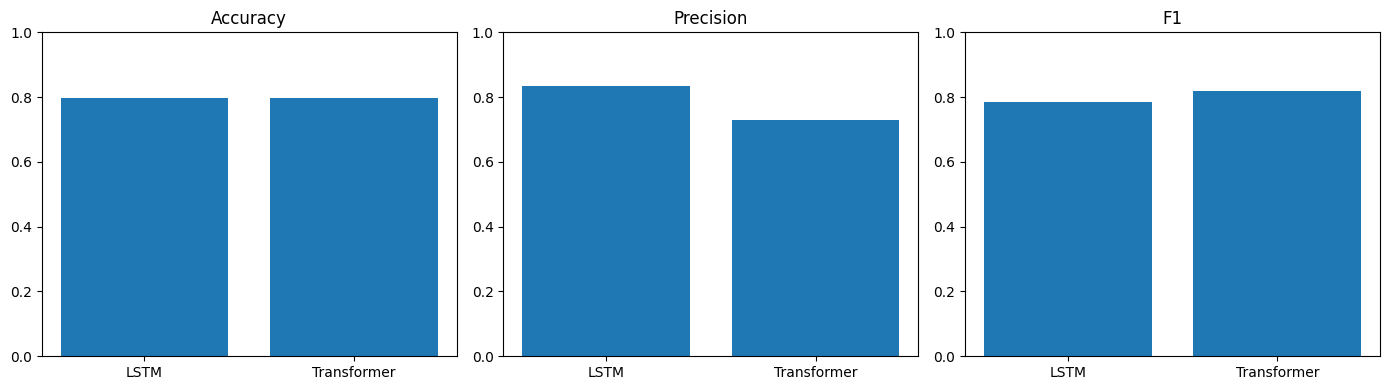

In [49]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4)
)

metrics = [
    ("Accuracy", "Accuracy"),
    ("Precision", "Precision"),
    ("F1", "F1")
]

for ax, (column, title) in zip(axes, metrics):

    ax.bar(
        df_comparison["Model"],
        df_comparison[column]
    )

    ax.set_title(title)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

# 22. Experiment 5 — Sequence length

In [50]:
def calculate_retained_tokens(df, max_length):

    total_tokens = 0
    retained_tokens = 0

    for tokens in df["words"]:

        length = len(tokens)

        total_tokens += length

        retained_tokens += min(
            length,
            max_length
        )

    percentage = (
        retained_tokens / max(total_tokens, 1)
    ) * 100

    return percentage

In [51]:
def calculate_attention_memory(
    batch_size,
    n_heads,
    max_length,
    num_layers=2
):

    elements = (
        batch_size
        * n_heads
        * max_length ** 2
    )

    # Float32 = 4 bytes
    memory_bytes = elements * 4

    memory_mb = memory_bytes / (1024 ** 2)

    # Nếu tính cả hai encoder layers
    total_memory_mb = memory_mb * num_layers

    return total_memory_mb

In [52]:
MAX_LENGTHS = [32, 64, 128, 256]

SEQUENCE_RESULTS = []

for max_length in MAX_LENGTHS:

    print("\n" + "=" * 55)
    print(f"Experiment max_length = {max_length}")
    print("=" * 55)

    # Tạo DataLoader mới
    train_loader, val_loader, test_loader = (
        create_loaders(max_length=max_length)
    )

    # Khởi tạo cùng kiến trúc
    model = TransformerClassifier(
        vocab_size=len(vocab),
        d_model=128,
        n_heads=4,
        num_layers=2,
        max_length=512
    )

    # Train
    model, training_time = train_model(
        model,
        train_loader,
        val_loader,
        epochs=5,
        learning_rate=0.001
    )

    # Test
    test_metrics = evaluate_model(
        model,
        test_loader
    )

    # Retained tokens
    retained = calculate_retained_tokens(
        test_df,
        max_length
    )

    # Attention memory
    attention_memory = calculate_attention_memory(
        batch_size=64,
        n_heads=4,
        max_length=max_length,
        num_layers=2
    )

    SEQUENCE_RESULTS.append({

        "Length": max_length,

        "Tokens retained (%)": retained,

        "Attention memory (MB)": attention_memory,

        "Training time (s)": training_time,

        "Accuracy": test_metrics["accuracy"],

        "F1": test_metrics["f1"]
    })

df_sequence = pd.DataFrame(
    SEQUENCE_RESULTS
)

display(df_sequence)


Experiment max_length = 32
Epoch 1/5 | Loss: 0.6263 | Val F1: 0.6994
Epoch 2/5 | Loss: 0.5283 | Val F1: 0.7351
Epoch 3/5 | Loss: 0.4353 | Val F1: 0.7097
Epoch 4/5 | Loss: 0.3380 | Val F1: 0.7192
Epoch 5/5 | Loss: 0.2443 | Val F1: 0.6887

Experiment max_length = 64
Epoch 1/5 | Loss: 0.5968 | Val F1: 0.7165
Epoch 2/5 | Loss: 0.4534 | Val F1: 0.7730
Epoch 3/5 | Loss: 0.3336 | Val F1: 0.7718
Epoch 4/5 | Loss: 0.2170 | Val F1: 0.7632
Epoch 5/5 | Loss: 0.1269 | Val F1: 0.7646

Experiment max_length = 128
Epoch 1/5 | Loss: 0.5467 | Val F1: 0.7992
Epoch 2/5 | Loss: 0.3630 | Val F1: 0.8183
Epoch 3/5 | Loss: 0.2334 | Val F1: 0.8260
Epoch 4/5 | Loss: 0.1302 | Val F1: 0.8151
Epoch 5/5 | Loss: 0.0626 | Val F1: 0.8134

Experiment max_length = 256
Epoch 1/5 | Loss: 0.5015 | Val F1: 0.8268
Epoch 2/5 | Loss: 0.3024 | Val F1: 0.8495
Epoch 3/5 | Loss: 0.1825 | Val F1: 0.8567
Epoch 4/5 | Loss: 0.0923 | Val F1: 0.8380
Epoch 5/5 | Loss: 0.0399 | Val F1: 0.8499


,Length,Tokens retained (%),Attention memory (MB),Training time (s),Accuracy,F1
0,32,14.001077,2.0,54.199601,0.700389,0.736471
1,64,27.649843,8.0,60.442825,0.765078,0.777265
2,128,52.029228,32.0,84.608627,0.817729,0.829523
3,256,77.550572,128.0,142.288648,0.848614,0.856682


In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

# Retained tokens
axes[0].plot(
    df_sequence["Length"],
    df_sequence["Tokens retained (%)"],
    marker="o"
)

axes[0].set_title("Tokens Retained")
axes[0].set_xlabel("Sequence Length")
axes[0].set_ylabel("Percentage (%)")

# Training time
axes[1].plot(
    df_sequence["Length"],
    df_sequence["Training time (s)"],
    marker="o"
)

axes[1].set_title("Training Time")
axes[1].set_xlabel("Sequence Length")
axes[1].set_ylabel("Seconds")

# F1
axes[2].plot(
    df_sequence["Length"],
    df_sequence["F1"],
    marker="o"
)

axes[2].set_title("F1 Score")
axes[2].set_xlabel("Sequence Length")
axes[2].set_ylabel("F1")

plt.tight_layout()
plt.show()

# 25. Experiment 6 — Pooling strategy

In [76]:
import re

def tokenize_text(text):

    text = text.lower().strip()

    tokens = re.findall(
        r"\b\w+\b|[^\w\s]",
        text
    )

    return tokens


text = "I really enjoyed this movie."

tokens = tokenize_text(text)

print("Raw text:", text)
print("Tokens:", tokens)

Raw text: I really enjoyed this movie.
Tokens: ['i', 'really', 'enjoyed', 'this', 'movie', '.']


In [64]:
def encode_text(
    text,
    vocab,
    max_length=128
):

    tokens = tokenize_text(text)

    # Truncate
    tokens = tokens[:max_length]

    # Token to IDs
    token_ids = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens
    ]

    return tokens, token_ids

text = "I really enjoyed this movie."

tokens, token_ids = encode_text(
    text,
    vocab,
    max_length=128
)

print("Tokens:", tokens)
print("Token IDs:", token_ids)

Tokens: ['i', 'really', 'enjoyed', 'this', 'movie', '.']
Token IDs: [9, 61, 463, 10, 20, 412]


In [65]:
if "<CLS>" not in vocab:
    vocab["<CLS>"] = len(vocab)

CLS_ID = vocab["<CLS>"]

print("CLS ID:", CLS_ID)
print("Vocabulary size:", len(vocab))

CLS ID: 306292
Vocabulary size: 306293


In [66]:
class IMDbTransformerDataset(Dataset):

    def __init__(
        self,
        df,
        vocab,
        max_length=128
    ):
        self.words = df["words"].tolist()
        self.labels = df["label"].tolist()

        self.vocab = vocab
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        tokens = self.words[idx]

        # Reserve one position for CLS
        tokens = tokens[:self.max_length - 1]

        token_ids = [
            self.vocab.get(
                token,
                self.vocab["<UNK>"]
            )
            for token in tokens
        ]

        # Add CLS at the beginning
        token_ids = [
            self.vocab["<CLS>"]
        ] + token_ids

        return (
            torch.tensor(
                token_ids,
                dtype=torch.long
            ),
            torch.tensor(
                float(self.labels[idx]),
                dtype=torch.float32
            )
        )


def create_pooling_loaders(max_length=128):

    train_dataset = IMDbTransformerDataset(
        train_df, vocab, max_length
    )

    val_dataset = IMDbTransformerDataset(
        val_df, vocab, max_length
    )

    test_dataset = IMDbTransformerDataset(
        test_df, vocab, max_length
    )

    generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_dataset,
        batch_size=64,
        shuffle=True,
        collate_fn=collate_fn,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=64,
        shuffle=False,
        collate_fn=collate_fn
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=64,
        shuffle=False,
        collate_fn=collate_fn
    )

    return train_loader, val_loader, test_loader

In [68]:
class TransformerPoolingClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        d_model=128,
        n_heads=4,
        num_layers=2,
        dropout=0.1,
        pooling="mean",
        max_length=512
    ):
        super().__init__()

        assert pooling in ["mean", "cls"]

        self.pooling = pooling

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=0
        )

        self.positional_encoding = PositionalEncoding(
            d_model,
            max_length
        )

        self.layers = nn.ModuleList([
            TransformerBlock(
                d_model,
                n_heads,
                dropout
            )
            for _ in range(num_layers)
        ])

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            d_model,
            1
        )

    def forward(self, input_ids):

        # Padding mask
        padding_mask = input_ids.eq(0)

        # Embedding
        x = self.embedding(input_ids)

        # Positional Encoding
        x = self.positional_encoding(x)

        # Transformer Encoder
        for layer in self.layers:

            x = layer(
                x,
                padding_mask=padding_mask
            )

        # Sequence representation
        if self.pooling == "mean":

            valid_mask = (
                ~padding_mask
            ).clone()

            # Exclude CLS token from mean pooling
            valid_mask[:, 0] = False

            mask = valid_mask.unsqueeze(-1)

            x = x.masked_fill(
                ~mask,
                0.0
            )

            pooled = x.sum(dim=1) / mask.sum(
                dim=1
            ).clamp(min=1)

        else:

            # First token is CLS
            pooled = x[:, 0, :]

        # Classifier
        pooled = self.dropout(pooled)

        logits = self.classifier(
            pooled
        ).squeeze(-1)

        return logits

In [69]:
train_loader, val_loader, test_loader = (
    create_pooling_loaders(
        max_length=128
    )
)

pooling_results = []

pooling_models = {}

for pooling_type in ["mean", "cls"]:

    print("\n" + "=" * 55)
    print(f"Training: {pooling_type.upper()} POOLING")
    print("=" * 55)

    # Reset seed for comparable initialization
    torch.manual_seed(42)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    model = TransformerPoolingClassifier(
        vocab_size=len(vocab),
        d_model=128,
        n_heads=4,
        num_layers=2,
        dropout=0.1,
        pooling=pooling_type,
        max_length=512
    )

    num_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    model, training_time = train_model(
        model,
        train_loader,
        val_loader,
        epochs=5,
        learning_rate=0.001
    )

    # Test evaluation
    test_metrics = evaluate_model(
        model,
        test_loader
    )

    pooling_models[pooling_type] = model

    pooling_results.append({

        "Pooling": pooling_type.upper(),

        "Parameters": num_params,

        "Training time (s)": training_time,

        "Accuracy": test_metrics["accuracy"],

        "Precision": test_metrics["precision"],

        "Recall": test_metrics["recall"],

        "F1": test_metrics["f1"]
    })

df_pooling = pd.DataFrame(pooling_results)

display(df_pooling)


Training: MEAN POOLING
Epoch 1/5 | Loss: 0.5528 | Val F1: 0.7674
Epoch 2/5 | Loss: 0.3599 | Val F1: 0.7891
Epoch 3/5 | Loss: 0.2302 | Val F1: 0.8088
Epoch 4/5 | Loss: 0.1235 | Val F1: 0.8189
Epoch 5/5 | Loss: 0.0572 | Val F1: 0.8148

Training: CLS POOLING
Epoch 1/5 | Loss: 0.5861 | Val F1: 0.7578
Epoch 2/5 | Loss: 0.4399 | Val F1: 0.8016
Epoch 3/5 | Loss: 0.3106 | Val F1: 0.8137
Epoch 4/5 | Loss: 0.1982 | Val F1: 0.8037
Epoch 5/5 | Loss: 0.1096 | Val F1: 0.8022


,Pooling,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,MEAN,39602177,85.069528,0.825511,0.828280,0.817513,0.822861
1,CLS,39602177,84.046245,0.804596,0.774933,0.853814,0.812464


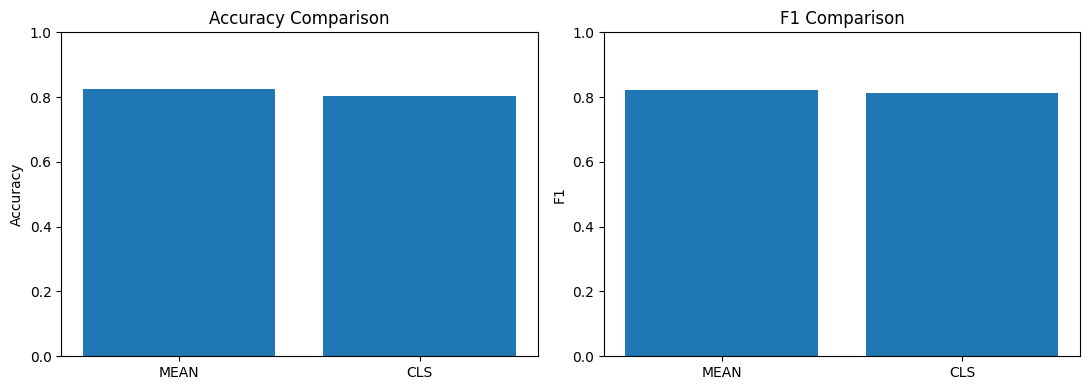

In [70]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

axes[0].bar(
    df_pooling["Pooling"],
    df_pooling["Accuracy"]
)

axes[0].set_title("Accuracy Comparison")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Accuracy")

axes[1].bar(
    df_pooling["Pooling"],
    df_pooling["F1"]
)

axes[1].set_title("F1 Comparison")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("F1")

plt.tight_layout()
plt.show()

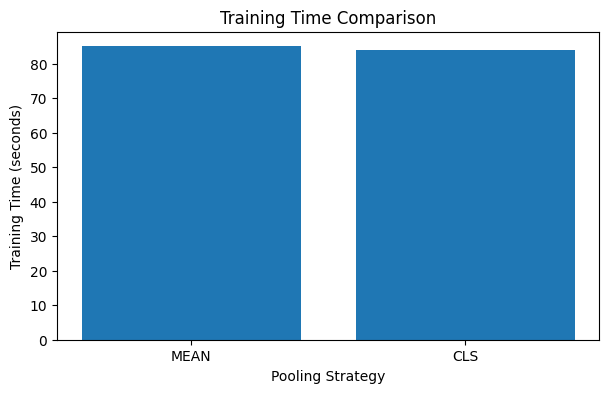

In [71]:
plt.figure(figsize=(7, 4))

plt.bar(
    df_pooling["Pooling"],
    df_pooling["Training time (s)"]
)

plt.title("Training Time Comparison")
plt.xlabel("Pooling Strategy")
plt.ylabel("Training Time (seconds)")

plt.show()

## Câu hỏi: Cách lấy sequence representation có ảnh hưởng tới classification không?
Có. Cách lấy sequence representation ảnh hưởng trực tiếp đến thông tin được truyền vào lớp Linear Classifier.
- Mean Pooling tổng hợp thông tin từ tất cả token representation bằng cách tính trung bình. Phương pháp này tận dụng thông tin toàn sequence nhưng có thể làm giảm ảnh hưởng của những token quan trọng.
- CLS-style Pooling sử dụng representation của token đặc biệt <CLS>. Thông qua Self-Attention, token này có khả năng tổng hợp thông tin từ các token khác trong sequence.
Hai phương pháp có thể tạo ra kết quả Accuracy và F1 khác nhau.

Tuy nhiên, không thể kết luận CLS luôn tốt hơn Mean Pooling. Kết quả phụ thuộc vào dataset, quá trình huấn luyện và kiến trúc Transformer.

# 23. Application — Transformer text classification

In [72]:
def predict_sentiment(
    text,
    model,
    vocab,
    max_length=128
):

    model.eval()

    # Step 1: Tokenization
    tokens = tokenize_text(text)

    # Step 2: Truncate
    tokens = tokens[:max_length - 1]

    # Step 3: Token to IDs
    token_ids = [
        vocab.get(
            token,
            vocab["<UNK>"]
        )
        for token in tokens
    ]

    # Step 4: Add CLS token
    token_ids = [
        vocab["<CLS>"]
    ] + token_ids

    # Step 5: Convert to Tensor
    input_ids = torch.tensor(
        [token_ids],
        dtype=torch.long
    ).to(DEVICE)

    # Step 6: Prediction
    with torch.no_grad():

        logits = model(input_ids)

        probability = torch.sigmoid(
            logits
        ).item()

    # Step 7: Classification
    prediction = (
        "Positive"
        if probability >= 0.5
        else "Negative"
    )

    return {
        "text": text,
        "tokens": tokens,
        "prediction": prediction,
        "positive_probability": probability,
        "negative_probability": 1 - probability
    }

In [73]:
test_cases = {

    "Short": (
        "Great movie!"
    ),

    "Long": (
        "I watched this movie last night and "
        "I was impressed by the performances. "
        "The actors did a wonderful job and "
        "the cinematography was beautiful. "
        "However, some scenes were too slow "
        "and the story could have been better. "
        "Overall, I enjoyed watching it and "
        "would recommend it to my friends."
    ),

    "Negation": (
        "I did not enjoy this movie."
    ),

    "Contrast": (
        "The acting was excellent, "
        "but the story was boring and "
        "the ending was disappointing."
    ),

    "Ambiguous": (
        "The movie was okay, with some good "
        "moments and some disappointing scenes."
    )
}

In [74]:
application_results = []

for case_name, text in test_cases.items():

    result = predict_sentiment(
        text,
        pooling_models["mean"],
        vocab,
        max_length=128
    )

    application_results.append({

        "Test Case": case_name,

        "Text": text,

        "Prediction": result["prediction"],

        "P(Positive)": result[
            "positive_probability"
        ],

        "P(Negative)": result[
            "negative_probability"
        ]
    })

df_application = pd.DataFrame(
    application_results
)

display(df_application)

,Test Case,Text,Prediction,P(Positive),P(Negative)
0,Short,Great movie!,Positive,0.888273,0.111727
1,Long,I watched this movie last night and I was impr...,Positive,0.998741,0.001259
2,Negation,I did not enjoy this movie.,Negative,0.000186,0.999814
3,Contrast,"The acting was excellent, but the story was bo...",Negative,0.002131,0.997869
4,Ambiguous,"The movie was okay, with some good moments and...",Negative,0.000272,0.999728
